# PandExo noise calculator

The JWST noise of one target with PandExo: the precision of a band's transit (or occultation) depth, converted to the noise per minute of light curve $\sigma_{\rm 1min}$ that the fits and retrievals use. PandExo needs the Pandeia reference data and the CDBS stellar models (environment variables `pandeia_refdata` and `PYSYN_CDBS`).

In [1]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")

import pandexo.engine.justdoit as jdi   # not called directly (run_pandexo imports it), but fails here if PandExo is missing
from hyperphase.bands import filter_lambda, instruments, PANDEXO_MODES
from hyperphase.noise import binning, NoNoiseLevelError, pandexo_params, rms_1min, rms_1min_pandexo, rms_1min_pandexo_sample, run_pandexo
from hyperphase.targets import hi_planets_by_name

In [2]:
# both environment variables must point to existing folders
for var in ("pandeia_refdata", "PYSYN_CDBS"):
    path = os.environ.get(var)
    print(f"{var:16s} {'ok     ' if path and os.path.isdir(path) else 'MISSING'} {os.path.basename(path.rstrip('/')) if path else '(not set)'}")   # the folder name only

pandeia_refdata  ok      pandeia_data-2026.7-jwst
PYSYN_CDBS       ok      trds


In [3]:
def plot_depth_precision(result, bins, ax):
    """Per-pixel transit-depth precision of a PandExo result (grey) and the white-light precision of each bin (orange); bins = [(l1, l2, sigma_ppm), ...] in um."""
    spec = result["FinalSpectrum"]
    ax.plot(spec["wave"], 1e6 * np.asarray(spec["error_w_floor"]), ".", color="0.6", ms=3, label="per pixel")
    for i, (l1, l2, sigma) in enumerate(bins):
        ax.hlines(sigma, l1, l2, color="C1", lw=2.5, label="per bin (white light)" if i == 0 else None)
    ax.set(yscale="log", xlabel="wavelength [µm]", ylabel="transit depth precision [ppm]")
    ax.legend()

## 1. Target

PandExo's inputs come from the archive (`pandexo_params`); T14 is passed from `PlanetParams`, which for a curated planet (`targets.CUSTOM`) such as TOI-2431 b follows from the published geometry.

In [4]:
name = "TOI-2431 b"
planet = hi_planets_by_name(name)
T14 = planet.T14   # transit duration [h]

print(f"{planet.name}: T14 = {T14:.4g} h (archive pl_trandur: {pandexo_params(name)['t14_h']:.4g} h)")

TOI-2431 b: T14 = 0.748 h (archive pl_trandur: 0.748 h)


## 2. MIRI/LRS

`run_pandexo` takes a band name, looks up its PandExo mode and prints every input with its source; any input can be overridden by keyword.

In [5]:
instrument = "MIRI/LRS"
result_lrs = run_pandexo(name, instrument, t14_h=T14)

PandExo inputs for TOI-2431 b  [instrument=MIRI/LRS (PandExo: MIRI LRS)]
    period     = 0.2242       d                <- pl_orbper
    rp_rearth  = 1.5139       R_earth          <- pl_rade
    rs_rsun    = 0.6513       R_sun            <- st_rad
    teff       = 4109         K                <- st_teff
    logg       = 4.68         log cgs          <- st_logg
    metal      = -0.02        log Fe/H         <- st_met
    t14_h      = 0.748        h                <- override
    mag        = 7.554        mag (sy_kmag)    <- sy_kmag
    ref_wave   = 2.22         um               <- sy_kmag
    fixed: sat_level=60, sat_unit=%, noccultations=1, R=None, baseline_unit=frac, baseline=1, noise_floor=0, star_type=phoenix, planet_type=constant, ngroup=optimize, background=ecliptic, background_level=high

Running Single Case w/ User Instrument Dict
Optimization Reqested: Computing Duty Cycle
Finished Duty Cycle Calc
Starting Out of Transit Simulation
End out of Transit
Starting In Transit Simula

In [6]:
pd.Series(result_lrs["timing"], name=instrument)

Transit Duration                              0.748000
Seconds per Frame                             0.156160
Time/Integration incl reset (sec)             1.873920
Measurement Time per Integration (sec)        1.561600
APT: Num Groups per Integration              11.000000
Num Integrations Out of Transit            1437.000000
Num Integrations In Transit                1437.000000
Num Superstripes                              1.000000
Effective Integrations Out of Transit      1437.000000
Effective Integrations In Transit          1437.000000
On Source Time Out of Transit              2244.019200
On Source Time In Transit                  2244.019200
Effective On Source Time Out of Transit    2244.019200
Effective On Source Time In Transit        2244.019200
APT: Num Integrations per Occultation      2874.000000
Observing Efficiency (%)                     83.333333
Transit+Baseline, no overhead (hrs)           1.496013
Number of Transits                            1.000000
Zero Frame

In [7]:
t_int = result_lrs["timing"]["Time/Integration incl reset (sec)"]   # cadence: one integration including the detector reset
print(f"{t_int:.3f} s per integration, {result_lrs['timing']['APT: Num Groups per Integration']} groups")

1.874 s per integration, 11 groups


### 2.1 Depth precision in wavelength bins

`binning(l1, l2, result)` sums the electrons of all pixels in [l1, l2] µm and returns the precision of that band's white-light depth (ppm per transit), here in twelve 0.6 µm bins.

In [8]:
edges = 5.06 + 0.609 * np.arange(13)
bins_lrs = [(l1, l2, binning(l1, l2, result_lrs, visualize=False)) for l1, l2 in zip(edges[:-1], edges[1:])]
for l1, l2, sigma in bins_lrs:
    print(f"{l1:6.3f}-{l2:6.3f} µm: {sigma:7.2f} ppm per transit")

 5.060- 5.669 µm:   30.46 ppm per transit
 5.669- 6.278 µm:   31.33 ppm per transit
 6.278- 6.887 µm:   33.41 ppm per transit
 6.887- 7.496 µm:   36.54 ppm per transit
 7.496- 8.105 µm:   40.08 ppm per transit
 8.105- 8.714 µm:   45.93 ppm per transit
 8.714- 9.323 µm:   50.79 ppm per transit
 9.323- 9.932 µm:   59.42 ppm per transit
 9.932-10.541 µm:   76.68 ppm per transit
10.541-11.150 µm:  116.33 ppm per transit
11.150-11.759 µm:  181.35 ppm per transit
11.759-12.368 µm:  324.35 ppm per transit


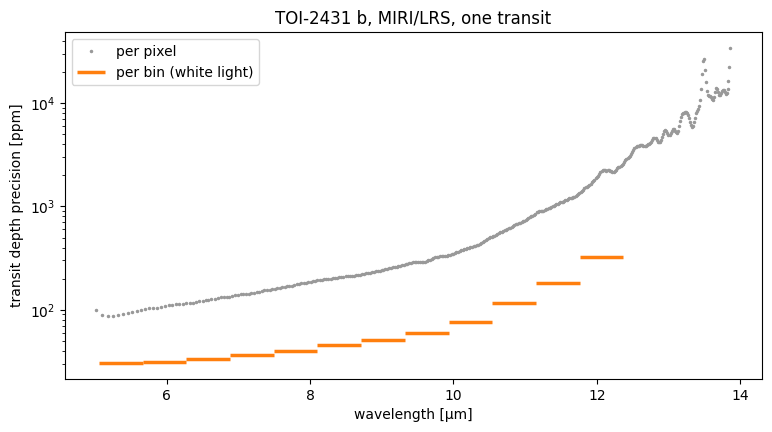

In [9]:
fig, ax = plt.subplots(figsize=(9, 4.5))
plot_depth_precision(result_lrs, bins_lrs, ax)
ax.set_title(f"{name}, MIRI/LRS, one transit")
plt.show()

The throughput drops at the red end, so the pipeline trims LRS to `filter_lambda("MIRI/LRS")`. One visit in that band, and two (÷√2):

In [10]:
l1, l2 = 1e6 * filter_lambda(instrument)   # [um]
sigma_lrs = binning(l1, l2, result_lrs, visualize=False)
print(f"{instrument} {l1:g}-{l2:g} µm: {sigma_lrs:.2f} ppm from one visit, {sigma_lrs / np.sqrt(2):.2f} ppm from two")
print(f"noise per minute (section 4): σ_1min = {rms_1min_pandexo(result_lrs, T14, filter_lambda(instrument)):.2f} ppm")

MIRI/LRS 5-10.5 µm: 13.28 ppm from one visit, 9.39 ppm from two
noise per minute (section 4): σ_1min = 62.93 ppm


## 3. NIRSpec G395H

One PandExo mode covers both detectors; the pipeline treats NRS1 and NRS2 as separate bands. `ngroup = 'optimize'` takes the most groups below 60 % full well; aim for at least ~5 groups per integration.

In [11]:
instrument = "JWST_NIRSpec.G395H_NRS1"   # either array key gives the same PandExo run ("NIRSpec G395H")
result_g395h = run_pandexo(name, instrument, t14_h=T14)

PandExo inputs for TOI-2431 b  [instrument=JWST_NIRSpec.G395H_NRS1 (PandExo: NIRSpec G395H)]
    period     = 0.2242       d                <- pl_orbper
    rp_rearth  = 1.5139       R_earth          <- pl_rade
    rs_rsun    = 0.6513       R_sun            <- st_rad
    teff       = 4109         K                <- st_teff
    logg       = 4.68         log cgs          <- st_logg
    metal      = -0.02        log Fe/H         <- st_met
    t14_h      = 0.748        h                <- override
    mag        = 7.554        mag (sy_kmag)    <- sy_kmag
    ref_wave   = 2.22         um               <- sy_kmag
    fixed: sat_level=60, sat_unit=%, noccultations=1, R=None, baseline_unit=frac, baseline=1, noise_floor=0, star_type=phoenix, planet_type=constant, ngroup=optimize, background=ecliptic, background_level=high

Running Single Case w/ User Instrument Dict
Optimization Reqested: Computing Duty Cycle
Finished Duty Cycle Calc
Starting Out of Transit Simulation
End out of Transit
Starti

In [12]:
bands_g395h = {"G395H (both arrays)": (2.87, 5.17),
               "NRS1": tuple(1e6 * filter_lambda("JWST_NIRSpec.G395H_NRS1")),
               "NRS2": tuple(1e6 * filter_lambda("JWST_NIRSpec.G395H_NRS2"))}
print(f"G395H: {result_g395h['timing']['APT: Num Groups per Integration']} groups per integration")
bins_g395h = [(l1, l2, binning(l1, l2, result_g395h, visualize=False)) for l1, l2 in bands_g395h.values()]
for label, (l1, l2, sigma) in zip(bands_g395h, bins_g395h):
    print(f"{label:20s} {l1:.2f}-{l2:.2f} µm: {sigma:6.2f} ppm per transit")
print(f"{'MIRI/LRS':20s} {1e6 * filter_lambda('MIRI/LRS')[0]:.2f}-{1e6 * filter_lambda('MIRI/LRS')[1]:.2f} µm: {sigma_lrs:6.2f} ppm per transit")

G395H: 5 groups per integration
G395H (both arrays)  2.87-5.17 µm:   6.38 ppm per transit
NRS1                 2.90-3.70 µm:   8.26 ppm per transit
NRS2                 3.80-5.20 µm:  10.43 ppm per transit
MIRI/LRS             5.00-10.50 µm:  13.28 ppm per transit


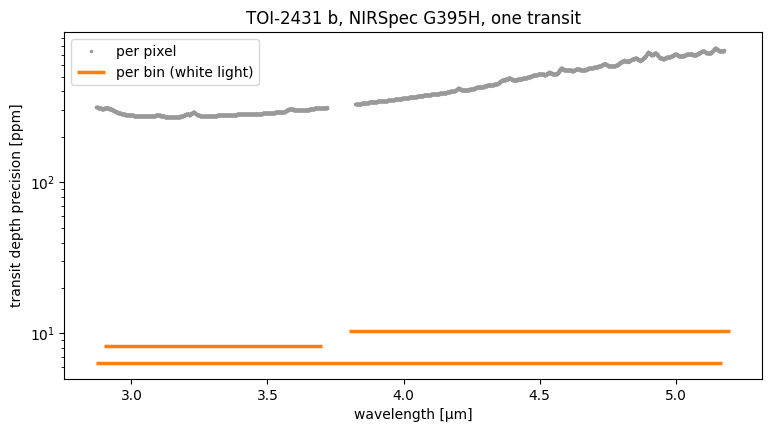

In [13]:
fig, ax = plt.subplots(figsize=(9, 4.5))
plot_depth_precision(result_g395h, bins_g395h, ax)
ax.set_title(f"{name}, NIRSpec G395H, one transit")
plt.show()

NIRSpec gives the smaller depth error, but at 3–5 µm the thermal depth is also smaller than in the mid-infrared: what counts is signal over noise.

## 4. From depth precision to σ_1min

The depth is measured against the out-of-transit baseline. With $N$ integrations of noise $\sigma_\mathrm{int}$ both in and out of transit:

$$\sigma_\mathrm{transit} = \sigma_\mathrm{int}\sqrt{\frac{1}{N_\mathrm{in}} + \frac{1}{N_\mathrm{out}}} = \sigma_\mathrm{int}\sqrt{\frac{2}{N}}, \qquad N = \frac{T_{14}}{t_\mathrm{int}}, \qquad \sigma_\mathrm{1min} = \sigma_\mathrm{int}\sqrt{\frac{t_\mathrm{int}}{60\,\mathrm{s}}}$$

$t_\mathrm{int}$ cancels: $\sigma_\mathrm{1min} = \sigma_\mathrm{transit}\sqrt{T_{14}/2\,\mathrm{min}}$. This holds for the settings `run_pandexo` fixes (one transit, equal time in and out of transit). `rms_1min_pandexo` does these steps; here by hand, for G395H over both arrays.

In [14]:
t_int = result_g395h["timing"]["Time/Integration incl reset (sec)"]   # [s]
N = T14 * 3600 / t_int                                                # integrations in transit (= out of transit)
sigma_transit = binning(2.87, 5.17, result_g395h, visualize=False)    # [ppm per transit]
sigma_int = sigma_transit / np.sqrt(2 / N)                            # [ppm per integration]
sigma_1min = sigma_int * np.sqrt(t_int / 60)                          # [ppm, one-minute integration]

print(f"t_int = {t_int:.3f} s  ->  N = {N:.0f} integrations in transit (PandExo's own count: {result_g395h['timing']['Num Integrations In Transit']})")
print(f"σ_transit = {sigma_transit:.2f} ppm,  σ_int = {sigma_int:.1f} ppm,  σ_1min = {sigma_1min:.2f} ppm")
assert np.isclose(sigma_1min, rms_1min_pandexo(result_g395h, T14, 1e-6 * np.array([2.87, 5.17])))

t_int = 5.412 s  ->  N = 498 integrations in transit (PandExo's own count: 498)
σ_transit = 6.38 ppm,  σ_int = 100.6 ppm,  σ_1min = 30.22 ppm


## 5. The `hyperphase.noise` PandExo functions

The pipeline calls only `rms_1min(planet, instrument)`. Its building blocks, in call order:

| function | returns |
|---|---|
| `bands.pandexo_mode(instrument)` | PandExo mode of a band |
| `pandexo_params(name, **overrides)` | PandExo inputs from the archive table |
| `run_pandexo(name, instrument, **overrides)` | PandExo result dict (native resolution, one visit) |
| `binning(l1, l2, result)` | white-light depth precision [ppm] in l1–l2 µm (plots by default; `visualize=False` to skip) |
| `rms_1min_pandexo(result, T14, lambda_range)` | σ_1min [ppm] for a band in m (`extra=True` for intermediates) |
| `rms_1min(planet, instrument)` | all of the above for one `PlanetParams` |
| `rms_1min_pandexo_sample(names, instrument)` | `{name: σ_1min}` for a sample |

### 5.1 Instruments and modes

In [15]:
for ins in instruments():
    l1, l2 = 1e6 * filter_lambda(ins)
    print(f"{ins:26s} {l1:5.1f}-{l2:5.1f} µm   PandExo mode: {PANDEXO_MODES[ins]}")

MIRI/F1280W                 11.6- 14.0 µm   PandExo mode: None
MIRI/F1500W                 13.5- 16.6 µm   PandExo mode: None
MIRI/F1800W                 16.5- 19.5 µm   PandExo mode: None
MIRI/LRS                     5.0- 10.5 µm   PandExo mode: MIRI LRS
Spitzer/IRAC2                4.0-  5.0 µm   PandExo mode: None
JWST_NIRSpec.G395H_NRS1      2.9-  3.7 µm   PandExo mode: NIRSpec G395H
JWST_NIRSpec.G395H_NRS2      3.8-  5.2 µm   PandExo mode: NIRSpec G395H


### 5.2 One planet, one band

`rms_1min` serves the cached value or runs PandExo on a miss, binned to `filter_lambda(instrument, planet)`, with T14 from the planet. It matches the step-by-step result.

In [16]:
print({k: round(float(v), 2) for k, v in rms_1min_pandexo(result_lrs, T14, filter_lambda("MIRI/LRS"), extra=True).items()})
sigma = rms_1min(planet, "MIRI/LRS", verbose=False)
print(f"rms_1min: {sigma:.2f} ppm")
assert np.isclose(sigma, rms_1min_pandexo(result_lrs, T14, filter_lambda("MIRI/LRS")))

{'Precision Transit': 13.28, 'Integration Duration': 1.87, 'RMS_1min_pandexo': 62.93}
rms_1min: 62.93 ppm


### 5.3 Instruments without a PandExo mode

MIRI imaging has no PandExo mode. `rms_1min` then returns the hand-entered value of `CUSTOM_SIGMA_1MIN` (`inputs/noise/custom_sigma_1min.csv`: S/N per integration and integration time, converted with `sigma_1min_from_integration`). For a planet without an entry it raises `NoNoiseLevelError`.

In [17]:
rms_1min(planet, "MIRI/F1500W", verbose=True)   # TOI-2431 b has an entry
try:
    rms_1min(hi_planets_by_name("K2-141 b"), "MIRI/F1500W")   # K2-141 b has none
except NoNoiseLevelError as err:
    print("NoNoiseLevelError:", err)

TOI-2431 b [MIRI/F1500W]: sigma_1min = 264.0 ppm from CUSTOM_SIGMA_1MIN (no PandExo mode)
NoNoiseLevelError: no noise level for 'K2-141 b' on 'MIRI/F1500W': PandExo has no mode for this instrument and inputs/noise/custom_sigma_1min.csv has no entry for this planet/instrument (it has none for this planet). Add one there, or pass sigma_1min by hand.


### 5.4 A sample

Values come from the PandExo caches where possible (`paths.PANDEXO_USER_CACHE`, then the shipped `inputs/noise/pandexo_cache.csv`); planets without a noise level are left out with a note.

In [18]:
sample = ["K2-141 b", "TOI-2431 b"]
for ins in ("JWST_NIRSpec.G395H_NRS2", "MIRI/F1500W"):
    sigmas = rms_1min_pandexo_sample(sample, ins)   # {name: sigma_1min [ppm]}
    print(ins, {k: round(float(v), 1) for k, v in sigmas.items()})

JWST_NIRSpec.G395H_NRS2 {'K2-141 b': 68.0, 'TOI-2431 b': 49.4}
no noise level on MIRI/F1500W (no PandExo mode and no CUSTOM_SIGMA_1MIN entry, or not observable: UNOBSERVABLE) for 1 of 2 planets: K2-141 b
MIRI/F1500W {'TOI-2431 b': 264.0}
